# Conectividade da rede cicloviária de Fortaleza

Este notebook verifica se as ciclovias e ciclofaixas existentes formam uma rede contínua ou conjuntos desconectados (ver `README.md`).

As tabelas são salvas em `resultados/` e a figura do artigo em `figuras/`.

In [1]:
import json
from datetime import date
from urllib.request import urlopen

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from shapely.ops import nearest_points

from rede import (BRUTOS, CRS_METRICO, FIGURAS, RESULTADOS, TOL_PRINCIPAL, TOLERANCIAS,
                  componentes, conexoes, grafo, ler_bruto, selecionar)

for pasta in (BRUTOS, RESULTADOS, FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)

URL_MALHA = ("https://dados.fortaleza.ce.gov.br/dataset/047e6dd6-cf6d-4a76-9ff0-0895d85bbf14/"
             "resource/e1f5e293-a452-4aa9-9357-b4e0f9f5a7a1/download/malha_cicloviaria.geojson")
URL_METADADOS = "https://dados.fortaleza.ce.gov.br/api/3/action/package_show?id=malha-cicloviaria"
URL_LIMITE = ("https://servicodados.ibge.gov.br/api/v3/malhas/municipios/2304400"
              "?formato=application/vnd.geo+json&qualidade=maxima")

## 1. Obtenção dos dados

Os arquivos são baixados apenas se ainda não existirem, para que a análise use sempre a mesma versão. A data de obtenção e os metadados do catálogo ficam em `resultados/fonte.json`.

In [2]:
arq_malha = BRUTOS / "malha_cicloviaria.geojson"
arq_limite = BRUTOS / "limite_fortaleza_ibge.geojson"
arq_fonte = RESULTADOS / "fonte.json"

for url, arq in [(URL_MALHA, arq_malha), (URL_LIMITE, arq_limite)]:
    if not arq.exists():
        arq.write_bytes(urlopen(url, timeout=60).read())

if not arq_fonte.exists():
    meta = json.load(urlopen(URL_METADADOS, timeout=60))["result"]
    fonte = {
        "url": URL_MALHA,
        "obtido_em": date.today().isoformat(),
        "catalogo_atualizado_em": meta["metadata_modified"],
        "recurso_atualizado_em": meta["resources"][0]["last_modified"],
        "licenca": meta["license_title"] or "não informada",
        "limite_municipal": URL_LIMITE,
    }
    arq_fonte.write_text(json.dumps(fonte, ensure_ascii=False, indent=2), encoding="utf-8")

fonte = json.loads(arq_fonte.read_text(encoding="utf-8"))
fonte

{'url': 'https://dados.fortaleza.ce.gov.br/dataset/047e6dd6-cf6d-4a76-9ff0-0895d85bbf14/resource/e1f5e293-a452-4aa9-9357-b4e0f9f5a7a1/download/malha_cicloviaria.geojson',
 'obtido_em': '2026-10-19',
 'catalogo_atualizado_em': '2024-06-07T18:30:30.646138',
 'recurso_atualizado_em': '2024-06-07T18:30:29.664691',
 'licenca': 'não informada',
 'limite_municipal': 'https://servicodados.ibge.gov.br/api/v3/malhas/municipios/2304400?formato=application/vnd.geo+json&qualidade=maxima'}

## 2. Inspeção e filtragem

Os campos de texto vêm com espaços extras. Ficam apenas ciclovias e ciclofaixas; ciclorrotas e passeios compartilhados são excluídos (ver README). Os comprimentos são calculados em coordenadas projetadas.

In [3]:
bruto = ler_bruto()
print(len(bruto), "trechos no arquivo")
print(bruto["Tipologia"].value_counts().to_string())
print("\nanoref:", bruto["anoref"].value_counts().to_dict())
print("geometrias:", bruto.geom_type.value_counts().to_dict())

447 trechos no arquivo
Tipologia
Ciclofaixas                313
Ciclovias                   93
Ciclorrotas                 32
Passeios compartilhados      9

anoref: {'  2022': 407, '  2023': 20, '  ': 14, '  2024': 3, '  2021': 1, '  202': 1, '  2020': 1}
geometrias: {'LineString': 447}


In [4]:
rede = selecionar(bruto)
rede["km_cadastro"] = pd.to_numeric(rede["Extensão (km)"].str.replace(",", "."), errors="coerce")

print(len(rede), "trechos;", round(rede["km"].sum(), 1), "km")
print(rede.groupby("Tipologia")["km"].agg(["count", "sum"]).round(1).to_string())
print("\ninválidas:", (~rede.is_valid).sum(), "| vazias:", rede.is_empty.sum(),
      "| geometrias duplicadas:", rede.geometry.normalize().to_wkb().duplicated().sum())
dif = (rede["km"] - rede["km_cadastro"]).abs()
print("diferença entre extensão medida e cadastrada: mediana",
      round(dif.median(), 3), "km; máx.", round(dif.max(), 2), "km")

406 trechos; 429.3 km
             count    sum
Tipologia                
Ciclofaixas    313  289.7
Ciclovias       93  139.6

inválidas: 0 | vazias: 0 | geometrias duplicadas: 0
diferença entre extensão medida e cadastrada: mediana 0.023 km; máx. 0.36 km


## 3. Construção da rede

Dois trechos são considerados conectados quando ocorre um destes casos:

- **extremidade**: uma extremidade de um trecho está a até `tol` metros de qualquer ponto do outro. Isso inclui encontros em "T" e ponta com ponta;
- **cruzamento**: os trechos se cruzam sem extremidade próxima. Pode ser cruzamento em nível ou passagem em níveis diferentes, por isso esses casos são exportados para conferência.

As funções estão em `rede.py`. Os componentes são calculados no grafo de adjacência entre trechos. Eles coincidem com os componentes do grafo em que os nós são extremidades e conexões e as arestas são os trechos, porque os dois grafos ligam os mesmos conjuntos de trechos. O grafo é não direcionado.

## 4. Sensibilidade à tolerância

A tolerância absorve pequenas imprecisões de desenho. Valores altos podem unir trechos separados por um cruzamento de via sem infraestrutura. Por isso o resultado é apresentado para várias tolerâncias, com e sem os cruzamentos.

In [5]:
total_km = rede["km"].sum()
linhas = []
for tol in TOLERANCIAS:
    for cruz in (False, True):
        c = componentes(rede, grafo(rede, tol, cruz))
        linhas.append({
            "tolerancia_m": tol, "com_cruzamentos": cruz,
            "componentes": len(c),
            "isolados": int((c["n_trechos"] == 1).sum()),
            "maior_km": c["km"].iloc[0],
            "maior_pct": 100 * c["km"].iloc[0] / total_km,
            "segundo_km": c["km"].iloc[1],
        })
sensibilidade = pd.DataFrame(linhas).round(1)
sensibilidade.to_csv(RESULTADOS / "sensibilidade_tolerancia.csv", index=False)
sensibilidade

,tolerancia_m,com_cruzamentos,componentes,isolados,maior_km,maior_pct,segundo_km
0,0,False,193,123,22.7,5.3,17.7
1,0,True,95,65,183.0,42.6,50.9
2,1,False,101,65,148.9,34.7,40.2
3,1,True,64,43,216.2,50.4,58.4
4,2,False,85,53,161.7,37.7,42.3
5,2,True,59,40,220.0,51.3,58.4
6,5,False,64,44,218.0,50.8,47.5
7,5,True,50,35,224.3,52.3,60.2
8,10,False,52,37,236.3,55.1,51.9
9,10,True,43,31,241.0,56.1,66.6


## 5. Cenário principal

Tolerância de 10 m, incluindo cruzamentos. As conexões que a triagem por imagem de satélite identificou como passagens em desnível (`resultados/triagem_conexoes.csv`, gerado com `triagem_conexoes.py`) são removidas.

In [6]:
triagem = pd.read_csv(RESULTADOS / "triagem_conexoes.csv")
desnivel = set(triagem.loc[triagem["veredito"] == "desnível", ["i", "j"]].itertuples(index=False, name=None))
inconclusivas = set(triagem.loc[triagem["veredito"] == "inconclusiva", ["i", "j"]].itertuples(index=False, name=None))
print(triagem["veredito"].value_counts().to_string())

for rotulo, excluir in [("sem triagem", set()), ("sem desníveis", desnivel),
                        ("sem desníveis e inconclusivas", desnivel | inconclusivas)]:
    c = componentes(rede, grafo(rede, TOL_PRINCIPAL, excluir=excluir))
    print(f"{rotulo:>30}: {len(c)} componentes; maior {c['km'].iloc[0]:.1f} km "
          f"({100 * c['km'].iloc[0] / total_km:.1f}%)")

veredito
em nível        48
confirmada      15
desnível        11
inconclusiva     3
                   sem triagem: 43 componentes; maior 241.0 km (56.1%)
                 sem desníveis: 44 componentes; maior 241.0 km (56.1%)
 sem desníveis e inconclusivas: 45 componentes; maior 236.4 km (55.1%)


In [7]:
pares = {par: tipo for par, tipo in conexoes(rede, TOL_PRINCIPAL).items() if par not in desnivel}
G = grafo(rede, TOL_PRINCIPAL, excluir=desnivel)
comp = componentes(rede, G)
rede["componente"] = 0
for ordem, nos in comp["trechos"].items():
    rede.loc[nos, "componente"] = ordem

print(len(comp), "componentes;", int((comp["n_trechos"] == 1).sum()), "com um único trecho")
print(f"maior componente: {comp['km'].iloc[0]:.1f} km "
      f"({100 * comp['km'].iloc[0] / total_km:.1f}% de {total_km:.1f} km)")
comp[["n_trechos", "km"]].head(10).round(2)

44 componentes; 32 com um único trecho
maior componente: 241.0 km (56.1% de 429.3 km)


,n_trechos,km
ordem,,
1,232,241.00
2,52,66.62
3,57,64.02
4,9,11.24
5,1,4.65
6,2,3.39
7,8,3.26
8,1,2.29
9,1,2.16


### Localização dos maiores conjuntos desconectados

Para cada componente, a tabela mostra a distância até o maior componente e os bairros atravessados. A distância é medida em linha reta e não corresponde ao percurso real.

In [8]:
maior = rede[rede["componente"] == 1].union_all()

def resumo(ordem):
    trechos = rede[rede["componente"] == ordem]
    bairros = sorted({b.strip() for s in trechos["Bairros"].dropna()
                      for b in s.split(",") if b.strip()})
    return {
        "ordem": ordem,
        "n_trechos": len(trechos),
        "km": round(trechos["km"].sum(), 2),
        "dist_maior_m": round(trechos.union_all().distance(maior)),
        "vias": "; ".join(sorted(trechos["Nome"].dropna().unique()))[:120],
        "bairros": ", ".join(bairros)[:120],
    }

desconectados = pd.DataFrame([resumo(o) for o in comp.index[1:]])
desconectados.to_csv(RESULTADOS / "componentes_desconectados.csv", index=False, encoding="utf-8-sig")
desconectados.head(15)

,ordem,n_trechos,km,dist_maior_m,vias,bairros
0,2,52,66.62,344,Av. Carneiro de Mendonça (parte 2); Av. Cel. M...,"Antônio Bezerra, Autran Nunes, Bom Jardim, Bon..."
1,3,57,64.02,686,Av. Cel. Miguel Dias; Av. Chanceler Edson Quei...,"Cambeba, Cidade dos Funcionários, Coaçu, Edson..."
2,4,9,11.24,62,Av. Alberto Craveiro; Av. Alberto Craveiro (pa...,"Aerolândia, Aeroporto, Boa Vista/Castelão, Dia..."
3,5,1,4.65,2197,Av. Quarto Anel Viário (parte 1),"Ancuri, Conjunto Palmeiras, Jangurussu, Pedras"
4,6,2,3.39,2922,Rio Cocó Leste (Cajazeiras) - parte 1; Rio Coc...,Cajazeiras
5,7,8,3.26,1160,Av. Castelo de Castro (parte 1); Av. Pompílio ...,"Barroso, Jangurussu, Passaré"
6,8,1,2.29,2123,Rio Maranguapinho Oeste (Canindezinho) - parte 1,Canindezinho
7,9,1,2.16,2674,Av. Min. Albuquerque Lima (Cj. Ceará),"Conjunto Ceará I, Conjunto Ceará II"
8,10,1,2.14,156,Ciclovia METROFOR,"Couto Fernandes, Demócrito Rocha, Itaoca, Mont..."
9,11,1,1.63,4976,Rua Crisanto Moreira da Rocha,Cambeba


### Conexões a conferir

São os cruzamentos sem extremidade próxima e as uniões que só aparecem com tolerância acima de 0 m. Conferir em imagem de satélite ou no Fortaleza em Mapas.

In [9]:
exatos = conexoes(rede, 0)
conferir = []
for (i, j), tipo in pares.items():
    if tipo == "cruzamento" or (i, j) not in exatos:
        a, b = rede.geometry[i], rede.geometry[j]
        pa, pb = nearest_points(a, b)
        ponto = gpd.GeoSeries([pa.union(pb).centroid], crs=rede.crs).to_crs(4326)[0]
        conferir.append({
            "tipo": tipo, "trecho_a": rede.at[i, "Nome"], "trecho_b": rede.at[j, "Nome"],
            "distancia_m": round(a.distance(b), 1),
            "lat": round(ponto.y, 6), "lon": round(ponto.x, 6),
        })
conferir = pd.DataFrame(conferir).sort_values(["tipo", "distancia_m"], ignore_index=True)
conferir.to_csv(RESULTADOS / "conexoes_a_conferir.csv", index=False, encoding="utf-8-sig")
print(conferir["tipo"].value_counts().to_string())
conferir.head(10)

tipo
extremidade    156
cruzamento     108


,tipo,trecho_a,trecho_b,distancia_m,lat,lon
0,cruzamento,Av. Eng. Humberto Monte,Rua Pe. Guerra,0.0,-3.740952,-38.567524
1,cruzamento,Av. Bezerra de Menezes,Rua Érico Mota,0.0,-3.735359,-38.563050
2,cruzamento,Rio Maranguapinho Leste (Autran Nunes),Av. Porto Velho,0.0,-3.761850,-38.594744
3,cruzamento,Rio Maranguapinho Leste (Bonsucesso),Rua Emílio de Menezes,0.0,-3.779900,-38.593954
4,cruzamento,Av. Aguanambi,Rua Pe. Miguelino/Pe. Matos Serra,0.0,-3.744064,-38.525639
5,cruzamento,Av. Aguanambi,Rua Coronel Solon/Saldanha Marinho,0.0,-3.742862,-38.525832
6,cruzamento,Av. Parsifal Barroso,Ligação Bezerra - Parsifal Barroso 1,0.0,-3.733625,-38.568978
7,cruzamento,Av. Des. Moreira,Rua Canuto de Aguiar,0.0,-3.730314,-38.496433
8,cruzamento,Av. Des. Moreira,Rua Ana Bilhar (parte 1),0.0,-3.729343,-38.496117
9,cruzamento,Rua Canuto de Aguiar,Rua Joaquim Nabuco,0.0,-3.729357,-38.499398


## 6. Figura do artigo

(a) Mapa da rede com os cinco maiores componentes destacados. (b) Extensão dos componentes em ordem decrescente, com as mesmas cores.

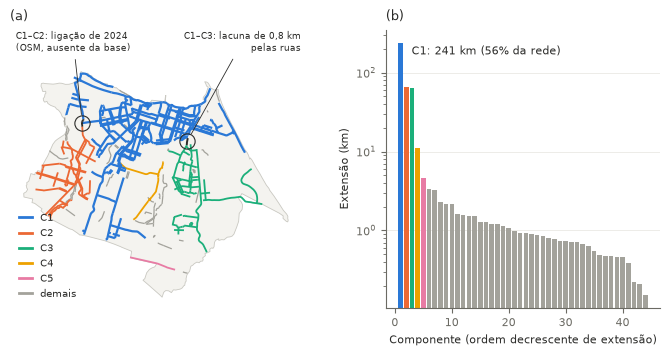

In [10]:
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # ordem fixa por posição
CINZA, TEXTO, TEXTO_2 = "#a3a29b", "#2b2b29", "#6b6a63"
N_DESTAQUE = len(CORES)

plt.rcParams.update({"font.family": "sans-serif", "font.size": 8,
                     "axes.edgecolor": TEXTO_2, "axes.labelcolor": TEXTO,
                     "xtick.color": TEXTO_2, "ytick.color": TEXTO_2})

limite = gpd.read_file(arq_limite).to_crs(CRS_METRICO)
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.0, 3.4),
                                 gridspec_kw={"width_ratios": [1.25, 1]})

limite.plot(ax=ax_a, facecolor="#f4f3ef", edgecolor="#c9c8c1", linewidth=0.6)
rede[rede["componente"] > N_DESTAQUE].plot(ax=ax_a, color=CINZA, linewidth=0.9)
for k in range(N_DESTAQUE, 0, -1):
    rede[rede["componente"] == k].plot(ax=ax_a, color=CORES[k - 1],
                                       linewidth=1.6 if k == 1 else 1.3)

# Ligações conferidas em conferir_lacunas.py: a de C2 já existe no OSM; a de C3 seria nova.
y0, y1 = ax_a.get_ylim()
ax_a.set_ylim(y0, y1 + 0.12 * (y1 - y0))  # espaço para os rótulos acima do mapa
lig = gpd.read_file(RESULTADOS / "lacunas.geojson").to_crs(CRS_METRICO)
marcas = [(lig.query("componente == 2 and tipo == 'OSM atual'"), "-",
           "C1–C2: ligação de 2024\n(OSM, ausente da base)", (0.02, 1.0), "left"),
          (lig.query("componente == 3 and tipo == 'pelas ruas'"), "--",
           "C1–C3: lacuna de 0,8 km\npelas ruas", (1.0, 1.0), "right")]
for sel, estilo, texto, pos, alinhamento in marcas:
    sel.plot(ax=ax_a, color=TEXTO, linewidth=1.4, linestyle=estilo)
    c = sel.union_all().centroid
    ax_a.plot(c.x, c.y, marker="o", markersize=11, markerfacecolor="none",
              markeredgecolor=TEXTO, markeredgewidth=0.8)
    ax_a.annotate(texto, xy=(c.x, c.y), xytext=pos, textcoords="axes fraction",
                  fontsize=6.5, color=TEXTO, ha=alinhamento, va="top",
                  arrowprops=dict(arrowstyle="-", color=TEXTO, linewidth=0.6, shrinkB=6))
ax_a.set_axis_off()
legenda = [Line2D([], [], color=c, lw=2, label=f"C{k}") for k, c in enumerate(CORES, 1)]
legenda.append(Line2D([], [], color=CINZA, lw=2, label="demais"))
ax_a.legend(handles=legenda, loc="lower left", frameon=False, fontsize=7,
            labelcolor=TEXTO, handlelength=1.4)

pct = 100 * comp["km"] / total_km
cores_barras = [CORES[k - 1] if k <= N_DESTAQUE else CINZA for k in comp.index]
ax_b.bar(comp.index, comp["km"], color=cores_barras, width=0.8)
ax_b.set_yscale("log")
ax_b.set_xlabel("Componente (ordem decrescente de extensão)")
ax_b.set_ylabel("Extensão (km)")
ax_b.spines[["top", "right"]].set_visible(False)
ax_b.grid(axis="y", color="#e6e5df", linewidth=0.5)
ax_b.set_axisbelow(True)
ax_b.annotate(f"C1: {comp['km'].iloc[0]:.0f} km ({pct.iloc[0]:.0f}% da rede)",
              xy=(1, comp["km"].iloc[0]), xytext=(8, -2), textcoords="offset points",
              va="top", color=TEXTO, fontsize=8)

fig.tight_layout()
topo = max(ax_a.get_position().y1, ax_b.get_position().y1) + 0.02
for ax, rotulo in [(ax_a, "(a)"), (ax_b, "(b)")]:
    fig.text(ax.get_position().x0, topo, rotulo, fontsize=9, color=TEXTO, va="bottom")
for ext in ("pdf", "png"):
    fig.savefig(FIGURAS / f"conectividade.{ext}", dpi=300, bbox_inches="tight")
plt.show()